# Part 2 — Data Quality & Panel

**BFT65B — Big Data Analytics in Finance | Student ID: 11230945**

Audit financial reporting quality, institutional events and temporal consistency using the verified Bronze source. Construct the Silver bank–quarter panel with explicit quality flags, event classifications and lineage verification. No modelling labels or fitted preprocessing are produced at this stage.

## 1. Repository and pinned runtime
Use a CPU runtime. Restore the repository and pinned dependencies before running the research commands.

In [1]:
from pathlib import Path
import os, sys, subprocess, json
REPO_URL = "https://github.com/NguyenDuong0508/11230945.git"
REPO = Path("/content/11230945")
if not REPO.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO)], check=True)
else:
    assert subprocess.check_output(["git", "remote", "get-url", "origin"], cwd=REPO, text=True).strip() == REPO_URL
    subprocess.run(["git", "pull", "--ff-only"], cwd=REPO, check=True)
print("Git revision:", subprocess.check_output(["git", "rev-parse", "HEAD"], cwd=REPO, text=True).strip())
subprocess.run([sys.executable, "-m", "pip", "install", "-r", str(REPO / "requirements.txt")], check=True)
def command(script, *args):
    subprocess.run([sys.executable, str(REPO / script), *map(str, args)], cwd=REPO, check=True)


Git revision: a5e9b869c4ebe1fa43412c5bb42b290a5360d0c3


## 2. Mandatory offline validation
Run the complete repository suite, including event-policy regression tests and Bronze-to-Silver Parquet integration. No skipped tests are accepted.

In [2]:
import xml.etree.ElementTree as ET
TESTS_PASSED = False
result_path = Path("/content/part2_tests.xml")
result_path.unlink(missing_ok=True)
result = subprocess.run([sys.executable, "-m", "pytest", "-q", "-ra", "--tb=short", "--show-capture=no", f"--junitxml={result_path}", "tests"], cwd=REPO,
                        env=dict(os.environ, PYTEST_DISABLE_PLUGIN_AUTOLOAD="1"), capture_output=True, text=True)
print(result.stdout)
if result.stderr:
    print(result.stderr)
if not result_path.is_file():
    raise RuntimeError("Missing pytest report")
cases = list(ET.parse(result_path).getroot().iter("testcase"))
problems = [(case, node) for case in cases for node in list(case) if node.tag in ("failure", "error", "skipped")]
for case, node in problems:
    print(case.get("classname"), case.get("name"), node.tag, node.get("message"), node.text or "")
if result.returncode or not cases or problems:
    raise RuntimeError("Offline validation failed; see diagnostics above")
TESTS_PASSED = True
print(f"Mandatory offline validation: PASS ({len(cases)} tests, zero skips)")


........................................................................ [ 50%]
......................................................................   [100%]
----------------- generated xml file: /content/part2_tests.xml -----------------
142 passed in 375.68s (0:06:15)

Mandatory offline validation: PASS (142 tests, zero skips)


## 3. Resolve and verify the Part 1 source
The active source pointer and the actual Bronze artifacts must agree. Do not copy a run ID or retrieve a different source snapshot.

In [3]:
from google.colab import drive
drive.mount("/content/drive")
WORKSPACE = Path("/content/drive/MyDrive/11230945")
assert TESTS_PASSED
assert not (WORKSPACE / "pending_source.json").exists(), "Complete acquisition first"
command("run_part1.py", "verify", "--workspace", WORKSPACE)
source_pointer = json.loads((WORKSPACE / "active_source.json").read_text())
SOURCE = WORKSPACE / source_pointer["path"]
print("Bronze manifest SHA-256:", source_pointer["manifest_sha256"])


Mounted at /content/drive
Bronze manifest SHA-256: e376152baac058e4dd4fff4582e9afa3c58820fff2f278115a82bff7fd4b3f6e


## 4. Build the Silver panel and event ledger
The build processes observed quarters in chronological order. It retains all source observations, masks only invalid asset denominators and nonfinite values, and retains financial quality flags. Conditional income differences and capital sensitivity statistics are not evidence of verified reporting semantics. Institutional and failure references are stored separately.

In [4]:
assert TESTS_PASSED
command("run_part2.py", "build", "--workspace", WORKSPACE)


## 5. Verify lineage and reconcile the panel
Recompute the deterministic transformations from Bronze, verify keys, values, schemas and reference ledgers, and check SHA-256 evidence. No downstream task uses an unverified Silver run.

In [5]:
command("run_part2.py", "verify", "--workspace", WORKSPACE)
import hashlib
pointer = json.loads((WORKSPACE / "active_panel.json").read_text())
SILVER = WORKSPACE / pointer["path"]
with (SILVER / "manifest.json").open("rb") as f:
    assert hashlib.file_digest(f,"sha256").hexdigest() == pointer["manifest_sha256"]
manifest = json.loads((SILVER / "manifest.json").read_text())
assert manifest["state"] == "VERIFIED"
assert manifest["source_manifest_sha256"] == source_pointer["manifest_sha256"]
assert manifest["summary"]["quarters"] == 170
assert manifest["summary"]["source_rows"] == manifest["summary"]["panel_rows"]
print("Silver manifest SHA-256:", pointer["manifest_sha256"])
print(json.dumps(manifest["summary"], indent=2))


Silver manifest SHA-256: f069efe97c0c05f8389e06acf6954536343726bdc3f15018ecdd073de43d59dc
{
  "asset_to_null": 0,
  "availability_assumption_days": 90,
  "bronze_failure_rows": 4117,
  "bronze_institution_rows": 27838,
  "distinct_certs": 24064,
  "event_diagnostics": {
    "assistance_records": 593,
    "duplicated_fin_values": 61,
    "end_dates_after_study_end": 4284,
    "failure_dates_before_first_report": 2,
    "failure_dates_before_last_report": 272,
    "failure_type_records": 3524,
    "invalid_or_missing_failure_dates": 0,
    "linked_distinct_failure_cert_dates_through_study_end": 2842,
    "linked_distinct_failure_certs_through_study_end": 2839,
    "missing_cert_failure_source_records": 488,
    "nonpositive_cert_failure_source_records": 0,
    "source_failure_records": 4117,
    "unknown_resolution_records": 0,
    "unknown_resolution_values": [],
    "unlinked_failure_type_records": 680
  },
  "event_ledger_rows": 31955,
  "gap_rows": 33,
  "historical_vintages_verified

## 6. Financial data quality and treatment
Inspect missingness, zeros, flagged observations and the documented treatment policy. Flag counts overlap; do not sum them as a count of invalid rows.

**Table 1. Source field quality**

field,rows,missing,zeros,negative,nonfinite,missing_pct,zero_pct
P3ASSET,"1,682,739","972,047","62,390",0,0,57.77,3.71
NTLNLS,"1,682,739","79,929","206,577","299,754",0,4.75,12.28
P9ASSET,"1,682,739","77,750","511,214",0,0,4.62,30.38
NAASSET,"1,682,739","77,749","323,574",2,0,4.62,19.23
ELNATR,"1,682,739","43,177","339,981","51,204",0,2.57,20.20
ROE,"1,682,739","18,746","1,904","162,113",0,1.11,0.11
BRO,"1,682,739","16,752","1,321,414",0,0,1.00,78.53
EINTEXP,"1,682,739","6,428","13,804",31,0,0.38,0.82
NETINC,"1,682,739","4,683","1,910","172,758",0,0.28,0.11
INTINC,"1,682,739","4,683",907,12,0,0.28,0.05


**Table 2. Automated quality flags**

rule,rows,flagged,flagged_pct,severity,treatment
ASSET_NONPOSITIVE,"1,682,739",0,0.000,invalid denominator,Set ASSET to null in Silver; retain row and flag; Bronze unchanged
CAPITAL_ZERO,"1,682,739","468,492",27.841,ambiguous reporting,Retain original zeros; separate sensitivity treatment
DEP_GT_ASSET,"1,682,739","6,205",0.369,review,Retain and flag; distressed balance sheets may be genuine
LOANS_GT_ASSET,"1,682,739",763,0.045,review,Retain and flag
NEGATIVE_DEP,"1,682,739",0,0.000,review,Retain and flag
NEGATIVE_EQUITY,"1,682,739","15,647",0.930,risk signal,Retain; not an automatic error
NEGATIVE_LOANS,"1,682,739",33,0.002,review,Retain and flag
NONCURRENT_GT_LOANS,"1,682,739",38,0.002,review,Retain and flag; verify scope and definitions
NONFINITE_VALUE,"1,682,739",0,0.000,invalid,Replace nonfinite numeric values with null and flag
REPORTING_GAP,"1,682,739",33,0.002,temporal review,No synthetic quarters or forward filling


**Figure 1. Observed banks by reporting quarter**

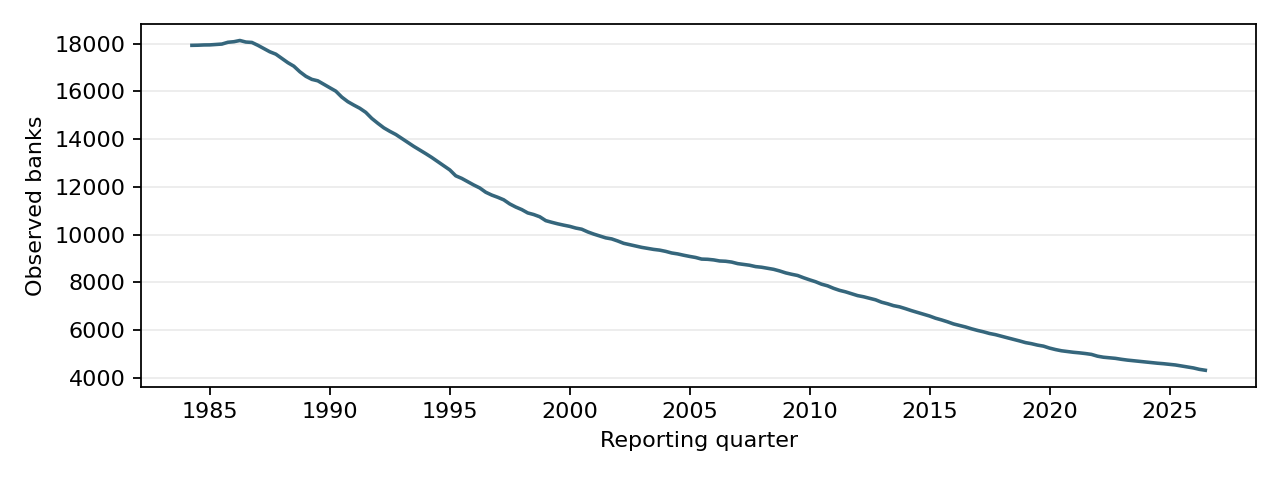

**Figure 2. Source field missingness**

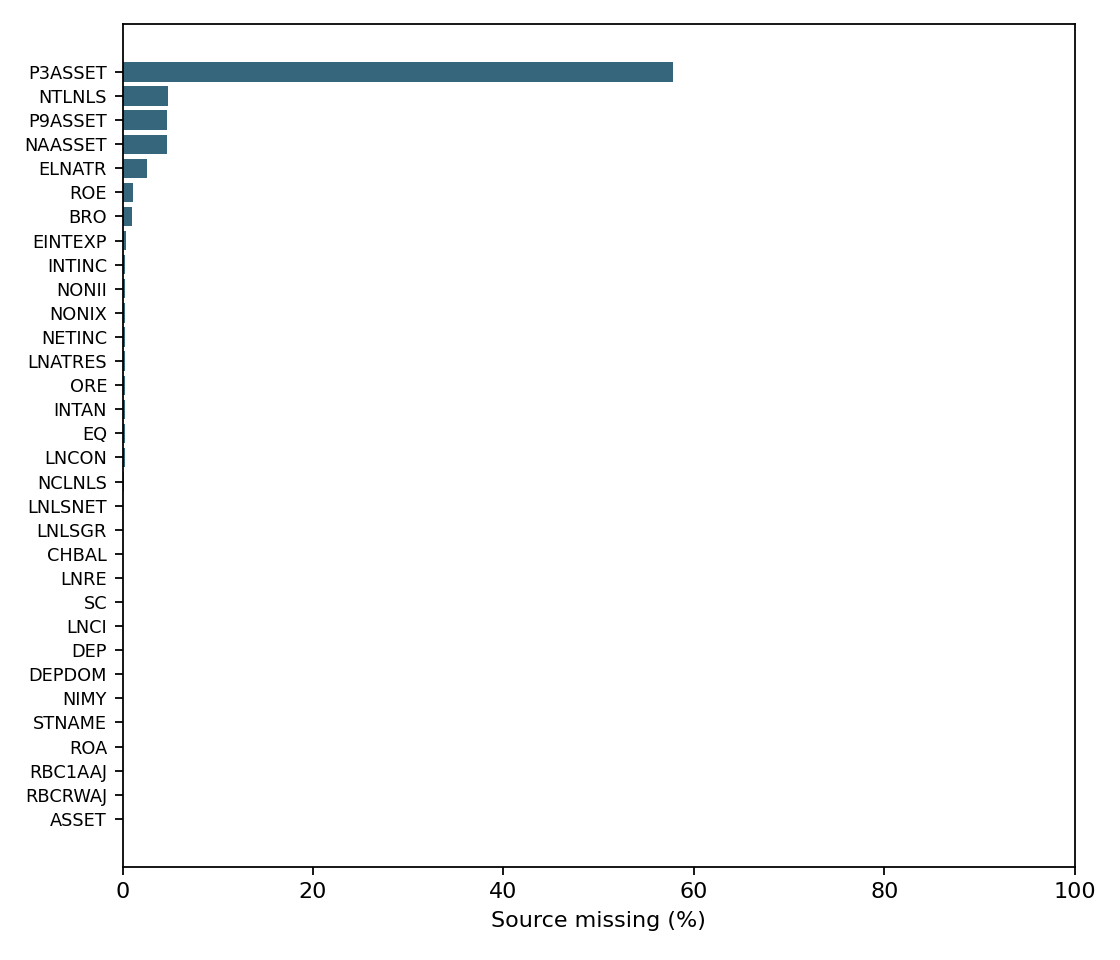

**Figure 3. Historical missingness by year**

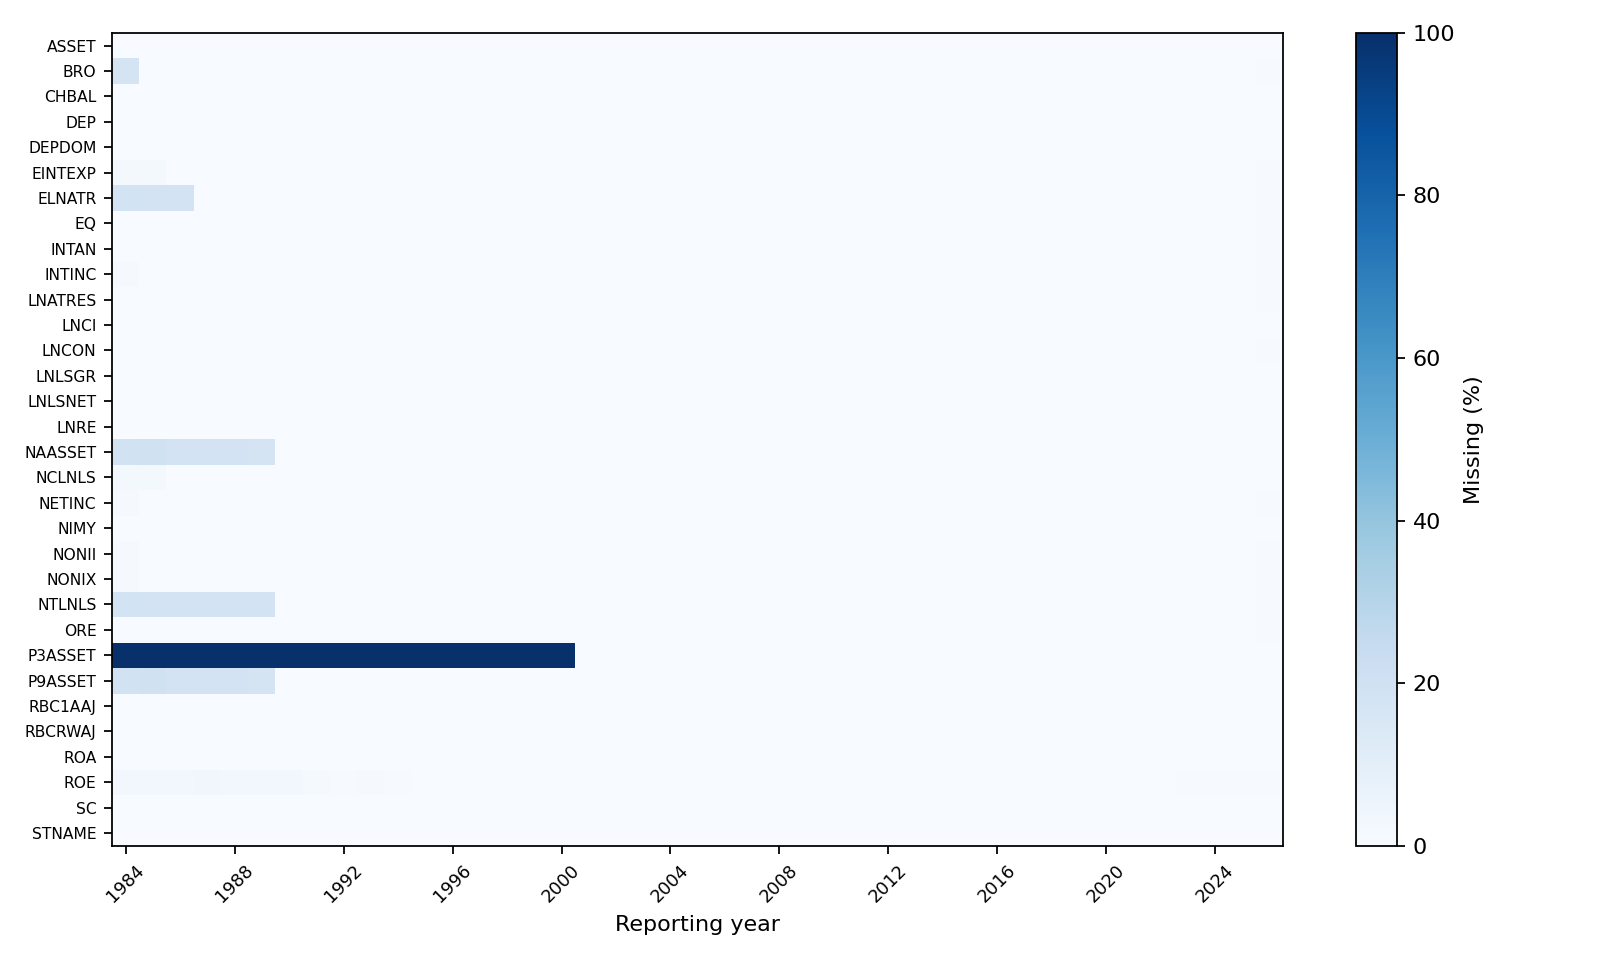

In [6]:
import pandas as pd
from IPython.display import display, Markdown, Image, HTML

def read(name):
    return pd.read_csv(SILVER / name)

def show(title, frame, formats=None):
    display(Markdown("**" + title + "**"))
    styled = frame.style.hide(axis="index").format(formats or {}, na_rep="—")
    display(styled)
    display(HTML('<div style="height:18px"></div>'))

def figure(title, name, width=680):
    display(Markdown("**" + title + "**"))
    display(Image(filename=str(SILVER / name), width=width))
    display(HTML('<div style="height:22px"></div>'))

fields = read("field_summary.csv").sort_values("missing_pct", ascending=False)
show("Table 1. Source field quality", fields, {"rows":"{:,}","missing":"{:,}","zeros":"{:,}","negative":"{:,}","nonfinite":"{:,}","missing_pct":"{:.2f}","zero_pct":"{:.2f}"})
flags = read("quality_flags.csv").groupby("rule", as_index=False)[["rows","flagged"]].sum()
flags["flagged_pct"] = 100*flags.flagged/flags.rows
show("Table 2. Automated quality flags", flags.merge(read("quality_policy.csv"),on="rule",validate="one_to_one"), {"rows":"{:,}","flagged":"{:,}","flagged_pct":"{:.3f}"})
figure("Figure 1. Observed banks by reporting quarter", "coverage.png")
figure("Figure 2. Source field missingness", "missingness.png", 580)
figure("Figure 3. Historical missingness by year", "historical_missingness.png")


## 7. Capital reporting and income-statement semantics
Zero capital ratios are retained in the primary panel. The separate sensitivity count treats zeros as missing without claiming that they represent CBLR elections. Income differences are conditional on a YTD basis and exact consecutive same-year reports. Do not treat them as verified quarterly flows across all regimes.

**Table 3. Capital reporting and zero-as-missing sensitivity**

regime,field,rows,zeros,missing,sensitivity_nonnull,zero_pct,missing_pct
2020_onward,RBC1AAJ,123462,442,0,123020,0.36,0.00
2020_onward,RBCRWAJ,123462,45864,0,77598,37.15,0.00
pre_2020,RBC1AAJ,1559277,79066,0,1480211,5.07,0.00
pre_2020,RBCRWAJ,1559277,422615,0,1136662,27.10,0.00


**Table 4. Conditional single-quarter income coverage**

reporting_regime,field,source_nonnull,candidate_nonnull,missing_predecessor,candidate_negative
2012_onward_call_reports,EINTEXP,323298,323221,77,428
2012_onward_call_reports,INTINC,323298,323221,77,389
2012_onward_call_reports,NETINC,323298,323221,77,22687
2012_onward_call_reports,NONII,323298,323221,77,5373
2012_onward_call_reports,NONIX,323298,323221,77,481
pre_2012_mixed,EINTEXP,1353013,1348455,4558,1833
pre_2012_mixed,INTINC,1354758,1349557,5201,1849
pre_2012_mixed,NETINC,1354758,1349557,5201,177419
pre_2012_mixed,NONII,1354758,1349557,5201,15441
pre_2012_mixed,NONIX,1354758,1349557,5201,2150


**Figure 4. Capital zero and missing rates by quarter**

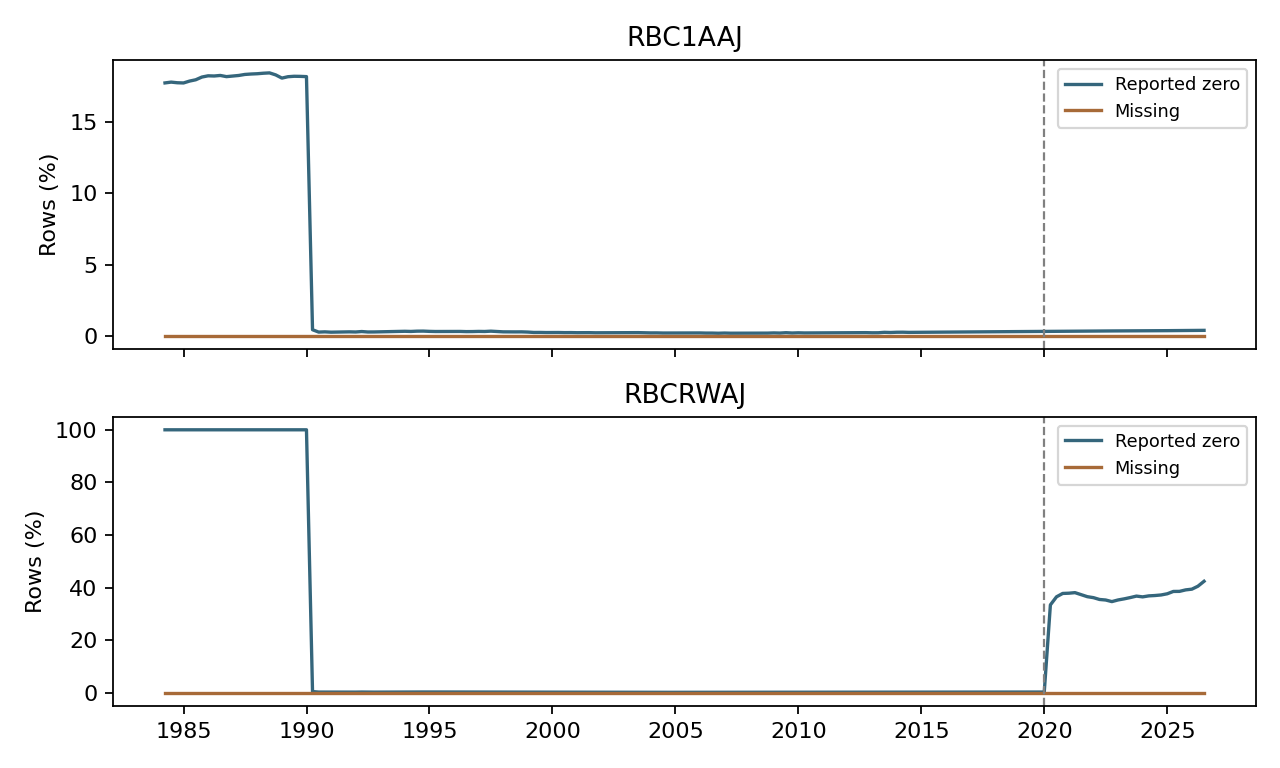

In [7]:
capital = read("capital_audit.csv").groupby(["regime","field"],as_index=False)[["rows","zeros","missing","sensitivity_nonnull"]].sum()
capital["zero_pct"] = 100*capital.zeros/capital.rows
capital["missing_pct"] = 100*capital.missing/capital.rows
show("Table 3. Capital reporting and zero-as-missing sensitivity", capital, {"zero_pct":"{:.2f}","missing_pct":"{:.2f}"})
flows = read("income_semantics_audit.csv").groupby(["reporting_regime","field"],as_index=False)[["source_nonnull","candidate_nonnull","missing_predecessor","candidate_negative"]].sum()
show("Table 4. Conditional single-quarter income coverage", flows)
figure("Figure 4. Capital zero and missing rates by quarter", "capital_reporting.png")


## 8. Institutional events and exit evidence
Distinguish explicit failure and assistance records from unknown resolution types and candidate institutional ends. A retrospective audit describes full-history inconsistencies; it is not a filter on the financial panel. Event counts are not counts of distinct failed institutions.

In [8]:
show("Table 5. Event ledger reconciliation", read("event_summary.csv"), {"records":"{:,}"})
show("Table 6. Retrospective institutional audit", read("terminal_summary.csv"), {"institutions":"{:,}"})
print(json.dumps(json.loads((SILVER/"event_diagnostics.json").read_text()),indent=2))


**Table 5. Event ledger reconciliation**

source,event_type,date_status,linked,records
failures,assistance,valid,False,154
failures,assistance,valid,True,439
failures,failure,valid,False,680
failures,failure,valid,True,"2,844"
institutions,institution_end,valid,False,"4,006"
institutions,institution_end,valid,True,"23,832"


**Table 6. Retrospective institutional audit**

audit_class,institutions
dated_other_end_candidate,"16,711"
end_precedes_last_report,3
failure_evidence,"2,570"
failure_precedes_last_report,266
multiple_failure_dates,3
observed_at_study_end,"4,314"
unresolved_discontinuation,197


{
  "assistance_records": 593,
  "duplicated_fin_values": 61,
  "end_dates_after_study_end": 4284,
  "failure_dates_before_first_report": 2,
  "failure_dates_before_last_report": 272,
  "failure_type_records": 3524,
  "invalid_or_missing_failure_dates": 0,
  "linked_distinct_failure_cert_dates_through_study_end": 2842,
  "linked_distinct_failure_certs_through_study_end": 2839,
  "missing_cert_failure_source_records": 488,
  "nonpositive_cert_failure_source_records": 0,
  "source_failure_records": 4117,
  "unknown_resolution_records": 0,
  "unknown_resolution_values": [],
  "unlinked_failure_type_records": 680
}


## 9. Point-in-time and outcome-policy diagnostics
The lag analysis describes source report availability under explicit assumptions; it does not establish historical filing timestamps or define the modelling risk set. The horizon diagnostic uses the separate event history and checks invariance to events after the outcome window.

In [9]:
timing = read("availability_sensitivity.csv")
import numpy as np
timing["quarter_offset"] = (pd.to_datetime(timing.decision_quarter).dt.year*4+pd.to_datetime(timing.decision_quarter).dt.quarter)-(pd.to_datetime(timing.report_quarter).dt.year*4+pd.to_datetime(timing.report_quarter).dt.quarter)
timing = timing.groupby(["lag_days","quarter_offset"],as_index=False)[["available_rows","report_rows"]].sum()
timing["available_pct"] = 100*timing.available_rows/timing.report_rows
show("Table 7. Report availability under alternative lags",timing,{"available_rows":"{:,}","report_rows":"{:,}","available_pct":"{:.2f}"})
case = json.loads((SILVER/"horizon_case.json").read_text())
print("Horizon diagnostic:",json.dumps(case,indent=2))
if case["observed_report"]:
    assert case["invariant"], "Horizon invariance failed"
else:
    print("Source report absent; synthetic regression tests provide the policy check.")


**Table 7. Report availability under alternative lags**

lag_days,quarter_offset,available_rows,report_rows,available_pct
60,0,0,"1,682,739",0.00
60,1,"1,682,739","1,682,739",100.00
60,2,"1,682,739","1,682,739",100.00
90,0,0,"1,682,739",0.00
90,1,"1,682,739","1,682,739",100.00
90,2,"1,682,739","1,682,739",100.00
120,0,0,"1,682,739",0.00
120,1,0,"1,682,739",0.00
120,2,"1,682,739","1,682,739",100.00
180,0,0,"1,682,739",0.00


Horizon diagnostic: {
  "CERT": 7213,
  "full_result": [
    0,
    "observed_at_horizon"
  ],
  "horizon_end": "2007-12-31",
  "invariant": true,
  "later_assistance_count": 1,
  "observed_report": true,
  "report_quarter": "2006-12-31",
  "truncated_result": [
    0,
    "observed_at_horizon"
  ]
}


## 10. Handoff
The active Silver pointer identifies the verified source and artifacts for Part 3 and Part 4. Part 3 reads the financial panel only. Part 4 establishes the decision-date risk set and final horizon-specific labels from the separate dated event evidence. Never use the retrospective terminal audit as a predictor or a blanket eligibility filter. Save the executed notebook with summary outputs; do not commit source or Silver data.